# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## 0. Setup

In [24]:
!pip install -q mlflow optuna


In [25]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [26]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [27]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [28]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()
def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

In [29]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


### Explicación del código de preprocesamiento

La función `preprocess_text` recibe un texto y dos parámetros configurables: `remove_stopwords` y `normalization`.

Primero se utiliza `word_tokenize` de NLTK para separar el texto en tokens. Luego se convierten los tokens a minúsculas y se conservan solamente aquellos que contienen caracteres alfabéticos mediante `isalpha()`.

Si `remove_stopwords` es verdadero, se eliminan las palabras pertenecientes al conjunto de stopwords en inglés.

Finalmente, según el valor de `normalization`, se aplica stemming mediante `PorterStemmer`, lematización mediante `WordNetLemmatizer` o no se realiza ninguna normalización.

La salida es un único string con los tokens separados por espacios, que luego puede ser procesado por `TfidfVectorizer`.



## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [30]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # TODO: crear un TfidfVectorizer con los parámetros recibidos y ajustarlo (fit) sobre train_texts,
    # después transformar train_texts y test_texts con ese mismo vectorizer.
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        norm='l2'
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


In [31]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### Explicación del código de vectorización

La función `vectorize_data` transforma los textos en representaciones numéricas mediante `TfidfVectorizer` de `scikit-learn`.

El vectorizador se ajusta únicamente sobre `train_texts` utilizando `fit_transform`. Luego se utiliza el mismo vectorizador para transformar `test_texts`.

Esto es importante porque el vocabulario y los valores de IDF se obtienen solamente a partir del conjunto de entrenamiento, evitando utilizar información del conjunto de prueba durante el ajuste del vectorizador.

Los hiperparámetros `ngram_range`, `max_features` y `min_df` permiten controlar el vocabulario utilizado por el modelo.

Además, se utiliza `norm='l2'` en `TfidfVectorizer`. Esto hace que cada vector TF-IDF quede normalizado en norma L2, controlando su magnitud y haciendo que la representación no dependa directamente de la longitud del documento.


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [32]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # TODO: definir una única capa lineal de input_dim a num_classes
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # TODO: devolver los logits (salida de self.linear), SIN aplicar softmax
        return self.linear(x)

In [33]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


### Explicación del modelo y del entrenamiento

El modelo `SoftmaxRegression` está implementado en PyTorch mediante una única capa `nn.Linear`. Esta capa recibe el vector TF-IDF de cada documento y genera un logit para cada una de las 20 categorías del dataset.

No se aplica ninguna función de activación ni `softmax` dentro del método `forward`. Los logits son enviados directamente a `CrossEntropyLoss`, que se utiliza como función de pérdida durante el entrenamiento.

El entrenamiento utiliza el optimizador Adam. En cada época se realiza el proceso de propagación hacia adelante, cálculo de la pérdida, backpropagation y actualización de los pesos.

Los valores de `loss` y `accuracy` de entrenamiento y validación se registran por época para poder analizar la dinámica del entrenamiento.

## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [34]:
%load_ext tensorboard


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [35]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history


### Explicación de la conversión a tensores y del entrenamiento

La función `to_tensor_dataset` adapta los datos generados por `TfidfVectorizer` al formato utilizado por PyTorch. Como TF-IDF genera inicialmente una matriz dispersa, se utiliza `X.toarray()` para convertirla a una matriz densa y luego se transforma en un tensor `float32`. Las etiquetas se convierten a tensores de tipo `long`, que es el tipo esperado por `CrossEntropyLoss`. Finalmente, ambos tensores se combinan mediante `TensorDataset`.

La función `train_softmax_model` implementa el ciclo de entrenamiento. En cada época, el modelo se coloca en modo entrenamiento mediante `model.train()`. Para cada batch se realiza el forward, se calcula la pérdida mediante `CrossEntropyLoss`, se ejecuta backpropagation con `loss.backward()` y se actualizan los parámetros mediante `optimizer.step()`.

Al finalizar cada época se calcula la pérdida y la accuracy del conjunto de entrenamiento. Luego el modelo pasa a modo evaluación mediante `model.eval()` y se utiliza `torch.no_grad()` para calcular las métricas sobre el conjunto de validación sin modificar los parámetros.

Las métricas obtenidas en cada época se almacenan en `history` y, cuando se proporciona un `SummaryWriter`, también se registran para poder visualizar la evolución del entrenamiento mediante TensorBoard.


## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [36]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [37]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Iniciamos una corrida anidada en MLflow para trackear este trial de manera individual
    with mlflow.start_run(run_name=f"optuna_trial_{trial.number}", nested=True):
        mlflow.log_params({
            "remove_stopwords": remove_stopwords,
            "normalization": normalization,
            "ngram_range": ngram_range,
            "max_features": max_features,
            "min_df": min_df,
            "lr": lr,
            "batch_size": batch_size,
        })

        history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}")

        best_val_acc = max(history["val_acc"])
        mlflow.log_metric("best_val_acc", best_val_acc)

    return history["val_acc"][-1]

# Configuramos el experimento de MLflow para agrupar las corridas
mlflow.set_experiment("softmax_20newsgroups")

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)

[I 2026-10-01 00:22:32,980] A new study created in memory with name: no-name-c17daf70-6754-4771-afdd-f516483009c8


[trial_0] Epoch 1/5 - train_loss: 1.5912 train_acc: 0.5824 - val_loss: 1.1064 val_acc: 0.6783
[trial_0] Epoch 2/5 - train_loss: 0.4719 train_acc: 0.8912 - val_loss: 1.0699 val_acc: 0.6757
[trial_0] Epoch 3/5 - train_loss: 0.2834 train_acc: 0.9480 - val_loss: 1.0907 val_acc: 0.6690
[trial_0] Epoch 4/5 - train_loss: 0.2055 train_acc: 0.9627 - val_loss: 1.1132 val_acc: 0.6633


[I 2026-10-01 00:22:38,577] Trial 0 finished with value: 0.6632788334069819 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.0814977397371914, 'batch_size': 128}. Best is trial 0 with value: 0.6632788334069819.


[trial_0] Epoch 5/5 - train_loss: 0.1674 train_acc: 0.9684 - val_loss: 1.1429 val_acc: 0.6633
[trial_1] Epoch 1/5 - train_loss: 1.9172 train_acc: 0.5783 - val_loss: 1.3299 val_acc: 0.6871
[trial_1] Epoch 2/5 - train_loss: 0.7668 train_acc: 0.8623 - val_loss: 1.1438 val_acc: 0.6880
[trial_1] Epoch 3/5 - train_loss: 0.4969 train_acc: 0.9206 - val_loss: 1.1013 val_acc: 0.6783
[trial_1] Epoch 4/5 - train_loss: 0.3636 train_acc: 0.9440 - val_loss: 1.0895 val_acc: 0.6783


[I 2026-10-01 00:22:44,150] Trial 1 finished with value: 0.6694653115333628 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.04032976783074735, 'batch_size': 128}. Best is trial 1 with value: 0.6694653115333628.


...

[trial_12] Epoch 5/5 - train_loss: 0.5814 train_acc: 0.9357 - val_loss: 1.1256 val_acc: 0.7243
[trial_13] Epoch 1/5 - train_loss: 2.3323 train_acc: 0.5783 - val_loss: 1.8071 val_acc: 0.7106
[trial_13] Epoch 2/5 - train_loss: 1.2975 train_acc: 0.8548 - val_loss: 1.3907 val_acc: 0.7282
[trial_13] Epoch 3/5 - train_loss: 0.8727 train_acc: 0.9000 - val_loss: 1.2114 val_acc: 0.7327
[trial_13] Epoch 4/5 - train_loss: 0.6504 train_acc: 0.9243 - val_loss: 1.1181 val_acc: 0.7304


[I 2026-10-01 00:24:47,133] Trial 13 finished with value: 0.7308882015024304 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.007785860044439444, 'batch_size': 32}. Best is trial 13 with value: 0.7308882015024304.


[trial_13] Epoch 5/5 - train_loss: 0.5137 train_acc: 0.9391 - val_loss: 1.0631 val_acc: 0.7309
[trial_14] Epoch 1/5 - train_loss: 2.1684 train_acc: 0.5746 - val_loss: 1.6166 val_acc: 0.6876
[trial_14] Epoch 2/5 - train_loss: 1.1270 train_acc: 0.8367 - val_loss: 1.2859 val_acc: 0.6969
[trial_14] Epoch 3/5 - train_loss: 0.7729 train_acc: 0.8853 - val_loss: 1.1586 val_acc: 0.6977
[trial_14] Epoch 4/5 - train_loss: 0.5870 train_acc: 0.9147 - val_loss: 1.0992 val_acc: 0.6955


[I 2026-10-01 00:24:57,553] Trial 14 finished with value: 0.692001767565179 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.010559823080349534, 'batch_size': 32}. Best is trial 13 with value: 0.7308882015024304.


[trial_14] Epoch 5/5 - train_loss: 0.4708 train_acc: 0.9311 - val_loss: 1.0701 val_acc: 0.6920
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.007785860044439444, 'batch_size': 32}
Mejor accuracy de validación: 0.7308882015024304


### Explicación de la búsqueda de hiperparámetros con Optuna

Antes de comenzar la búsqueda se construye `preprocessed_cache`, donde se almacenan las seis combinaciones posibles de eliminación de stopwords y normalización lingüística. De esta manera, el procesamiento de los textos no debe repetirse en cada trial de Optuna.

La función `objective` define el experimento que Optuna debe optimizar. En cada trial se seleccionan automáticamente los hiperparámetros de preprocesamiento, vectorización y entrenamiento dentro del espacio de búsqueda definido.

Luego se divide el conjunto de entrenamiento en una parte para entrenamiento y otra para validación mediante `train_test_split`, utilizando `stratify` para conservar la distribución de las clases. El conjunto de test original no se utiliza durante esta búsqueda.

Para cada combinación se crea el vectorizador TF-IDF, se construyen los `DataLoader`, se inicializa una nueva regresión Softmax y se entrena durante cinco épocas. La accuracy de validación obtenida en la última época es el valor que se devuelve a Optuna y es el que utiliza para comparar los trials.

También se registra cada trial mediante MLflow, guardando sus hiperparámetros y la mejor accuracy de validación alcanzada durante sus cinco épocas.


In [ ]:
import pandas as pd

# Resumen de los trials realizados por Optuna
trials_df = study.trials_dataframe(
    attrs=("number", "value", "state", "datetime_start", "datetime_complete")
)

trials_df["duration_s"] = (
    pd.to_datetime(trials_df["datetime_complete"])
    - pd.to_datetime(trials_df["datetime_start"])
).dt.total_seconds()

trials_df = trials_df.sort_values("value", ascending=False)

display(trials_df[["number", "value", "state", "duration_s"]].head(10))

In [47]:
# Resumen completo de todos los trials de Optuna
trials_full = study.trials_dataframe()

cols = [
    "number",
    "value",
    "duration",
    "params_remove_stopwords",
    "params_normalization",
    "params_ngram_range",
    "params_max_features",
    "params_min_df",
    "params_lr",
    "params_batch_size",
]

trials_full = trials_full[cols].sort_values("value", ascending=False)

display(trials_full)

,number,value,duration,params_remove_stopwords,params_normalization,params_ngram_range,params_max_features,params_min_df,params_lr,params_batch_size
13,13,0.730888,0 days 00:00:08.783140,True,lemmatize,1gram,10000,2,0.007786,32
12,12,0.724260,0 days 00:00:08.174729,True,none,1gram,10000,2,0.006695,32
4,4,0.720283,0 days 00:00:10.392185,True,none,1gram,10000,2,0.009996,32
10,10,0.714096,0 days 00:00:10.426379,False,none,1gram,10000,2,0.002375,32
3,3,0.709677,0 days 00:00:15.249500,True,none,1_2gram,10000,5,0.012578,32
11,11,0.700840,0 days 00:00:09.553235,False,none,1gram,10000,2,0.029875,32
14,14,0.692002,0 days 00:00:10.418456,True,lemmatize,1_2gram,5000,2,0.010560,32
1,1,0.669465,0 days 00:00:05.570687,True,none,1gram,5000,2,0.040330,128
0,0,0.663279,0 days 00:00:05.595403,True,none,1gram,5000,2,0.081498,128
8,8,0.645603,0 days 00:00:11.977393,False,lemmatize,1_2gram,5000,1,0.010919,64


### Análisis de los resultados de la búsqueda de hiperparámetros

Optuna realizó 15 trials y seleccionó como mejor configuración la correspondiente al trial 13, con una accuracy de validación de aproximadamente `0.7309`.

Los hiperparámetros seleccionados fueron:

* `remove_stopwords = True`
* `normalization = lemmatize`
* `ngram_range = (1, 1)`, es decir, solamente unigramas
* `max_features = 10000`
* `min_df = 2`
* `lr ≈ 0.00779`
* `batch_size = 32`

La configuración seleccionada utiliza lematización y eliminación de stopwords. Además, utiliza únicamente unigramas y un vocabulario limitado a 10000 características, descartando términos que aparecen en menos de 2 documentos.

Las seis mejores configuraciones usan 10000 características y min_df ≥ 2, y la mayoría no aplica normalización: solo el trial 13 lematiza. El trial 6 tiene 10000 características pero obtuvo 0.630, con el lr más bajo (0.0016) y todavía mejorando en la época 5. Los trials con stemming (2, 5, 6, 7) quedaron entre 0.575 y 0.630, pero también usan bigramas y tienen lr extremos o vocabularios chicos, por lo que esa diferencia no puede atribuirse al stemming. La ventaja de lematizar (0.7309) sobre no normalizar (0.7243, trial 12) equivale a unos 15 documentos sobre 2263 de validación.

También se observa una influencia importante del learning rate. Para configuraciones similares, valores muy pequeños producen una mejora más lenta durante las cinco épocas, mientras que un learning rate demasiado elevado puede provocar una mejora muy rápida de la accuracy de entrenamiento pero una disminución posterior de la accuracy de validación.

Respecto de los n-gramas, 7 de los 15 trials usaron bigramas; el mejor fue el trial 3 con 0.7097, por debajo del mejor con unigramas. Como esos trials difieren también en vocabulario y lr, no se puede concluir de forma aislada que los bigramas perjudiquen.

Es importante tener en cuenta que Optuna optimizó únicamente 15 configuraciones. Por lo tanto, estos resultados representan la mejor configuración encontrada dentro del espacio de búsqueda y de las pruebas realizadas, pero no permiten afirmar que sea la configuración óptima global.

Un detalle importante de la búsqueda es que la función `objective` devuelve `history["val_acc"][-1]`. Por lo tanto, Optuna compara los trials utilizando la accuracy de validación obtenida exclusivamente en la quinta época, y no la máxima accuracy alcanzada a lo largo del proceso. Esto permite evaluar todas las configuraciones bajo un presupuesto idéntico y estandarizado de cinco épocas.

### Frameworks y herramientas utilizadas

**PyTorch:** se utiliza para implementar la regresión softmax, definir la función de pérdida `CrossEntropyLoss`, realizar el entrenamiento mediante backpropagation y utilizar el optimizador Adam.

**scikit-learn:** se utiliza para cargar el dataset 20 Newsgroups, realizar la vectorización TF-IDF y calcular métricas como accuracy, classification report y matriz de confusión.

**NLTK:** se utiliza para el procesamiento del lenguaje natural, incluyendo tokenización, stopwords, stemming y lematización.

**Optuna:** se utiliza para realizar la búsqueda automática de hiperparámetros. En este trabajo se optimizan conjuntamente parámetros de preprocesamiento, vectorización y entrenamiento.

**TensorBoard:** se utiliza para visualizar la evolución de `loss` y `accuracy` durante el entrenamiento.

**MLflow:** se utiliza para registrar parámetros, métricas y el modelo entrenado, permitiendo guardar y consultar los resultados de los experimentos.

**Matplotlib:** se utiliza para generar la matriz de confusión y visualizar los resultados.

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [40]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 20

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                 batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                                batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)
writer = SummaryWriter(log_dir="runs/softmax_final")
mlflow.end_run()
mlflow.set_experiment("softmax_20newsgroups")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({
        "remove_stopwords": BEST_REMOVE_SW, "normalization": BEST_NORM,
        "ngram_range": str(BEST_NGRAM), "max_features": BEST_MAX_FEATURES, "min_df": BEST_MIN_DF,
        "lr": BEST_LR, "batch_size": BEST_BATCH_SIZE, "epochs": EPOCHS_FINAL,
    })
    history = train_softmax_model(model, train_loader_final, test_loader_final, optimizer,
                                   epochs=EPOCHS_FINAL, writer=writer, run_name="final")
    # Usamos 'pickle' para guardar el modelo sin requerir un input_example obligatorio de 'pt2'
    mlflow.pytorch.log_model(model, "model", serialization_format="pickle")

writer.close()

[final] Epoch 1/20 - train_loss: 2.2144 train_acc: 0.6072 - val_loss: 1.7919 val_acc: 0.6576
[final] Epoch 2/20 - train_loss: 1.1725 train_acc: 0.8525 - val_loss: 1.4492 val_acc: 0.6693
[final] Epoch 3/20 - train_loss: 0.7916 train_acc: 0.8946 - val_loss: 1.3136 val_acc: 0.6703
[final] Epoch 4/20 - train_loss: 0.5942 train_acc: 0.9215 - val_loss: 1.2482 val_acc: 0.6719
[final] Epoch 5/20 - train_loss: 0.4725 train_acc: 0.9358 - val_loss: 1.2137 val_acc: 0.6705
[final] Epoch 6/20 - train_loss: 0.3901 train_acc: 0.9466 - val_loss: 1.1939 val_acc: 0.6683
[final] Epoch 7/20 - train_loss: 0.3305 train_acc: 0.9540 - val_loss: 1.1849 val_acc: 0.6658
[final] Epoch 8/20 - train_loss: 0.2859 train_acc: 0.9585 - val_loss: 1.1821 val_acc: 0.6630
[final] Epoch 9/20 - train_loss: 0.2513 train_acc: 0.9617 - val_loss: 1.1836 val_acc: 0.6613
[final] Epoch 10/20 - train_loss: 0.2242 train_acc: 0.9646 - val_loss: 1.1885 val_acc: 0.6597
[final] Epoch 11/20 - train_loss: 0.2024 train_acc: 0.9664 - val_loss

2026/10/01 00:25:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/01 00:25:36 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/01 00:25:36 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


[final] Epoch 20/20 - train_loss: 0.1170 train_acc: 0.9715 - val_loss: 1.2988 val_acc: 0.6438


2026/10/01 00:25:42 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


### Análisis de la dinámica de distintos entrenamientos

La evolución de las métricas muestra comportamientos diferentes según los hiperparámetros utilizados.

Un caso claro de comportamiento desfavorable por sobreajuste rápido o inestabilidad es el **Trial 7**, que utiliza un learning rate elevado de aproximadamente `0.0816`. En este caso, la accuracy de entrenamiento aumenta significativamente desde `0.552` hasta aproximadamente `0.973`, pero la accuracy de validación disminuye desde `0.630` hasta `0.616` al finalizar las cinco épocas. Esto evidencia de forma clara cómo el modelo memoriza el conjunto de entrenamiento pero pierde capacidad de generalización sobre datos no observados.

El **Trial 13**, seleccionado como la mejor configuración encontrada por Optuna, muestra un aprendizaje sumamente interesante y consistente a lo largo de las cinco épocas:
* **Época 1:** `0.7106` (accuracy de validación)
* **Época 2:** `0.7282`
* **Época 3:** `0.7327`
* **Época 4:** `0.7304`
* **Época 5:** `0.7309`

Este comportamiento denota un progreso rápido y mucho más estable que en otras configuraciones, estabilizándose por encima del `73%` de accuracy de validación.

Estos ejemplos ilustran que el learning rate y la correcta regularización o selección de características (mediante el vocabulario y la lematización) no solo dictan la precisión final, sino también la estabilidad y la suavidad de las curvas de aprendizaje.

In [ ]:
# Verificación rápida de los experimentos guardados en MLflow
import mlflow

# Obtener el experimento por su nombre
experiment = mlflow.get_experiment_by_name("softmax_20newsgroups")

if experiment:
    # Buscar las corridas del experimento
    runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
    print(f"¡Éxito! Encontramos el experimento: '{experiment.name}'")
    print(f"Cantidad de entrenamientos registrados: {len(runs)}\n")

    # Mostrar detalles de la última corrida (el entrenamiento final)
    if not runs.empty:
        latest_run = runs.iloc[0]
        print("=== DETALLES DE LA ÚLTIMA CORRIDA ===")
        print(f"ID de Corrida: {latest_run['run_id']}")
        print(f"Nombre de Corrida: {latest_run['tags.mlflow.runName']}")
        print(f"Estado: {latest_run['status']}")
        print("\n--- Hiperparámetros guardados ---")
        for col in runs.columns:
            if col.startswith("params."):
                print(f"  {col.replace('params.', '')}: {latest_run[col]}")
else:
    print("No se encontró el experimento. Asegúrate de haber ejecutado la celda anterior de entrenamiento.")

In [ ]:
%tensorboard --logdir runs


### Análisis de tiempos de los trials y convergencia

Los trials de Optuna fueron evaluados durante cinco épocas, por lo que las duraciones registradas nos permiten comparar el costo computacional total de las diferentes configuraciones en el proceso de búsqueda.

Estas duraciones totales de cada trial presentan variaciones notorias según la complejidad del vocabulario y los parámetros seleccionados:
* El **Trial 13** (que obtuvo la mejor accuracy de validación de `0.7309`) tuvo una duración total de aproximadamente `8.78 s`.
* El **Trial 12** finalizó en aproximadamente `8.18 s`.
* El **Trial 3** requirió aproximadamente `15.25 s`.
* El **Trial 9** fue uno de los más rápidos, completándose en aproximadamente `3.74 s`.

Es fundamental destacar que estas métricas representan la **duración total del trial de Optuna** (que engloba la vectorización de los textos mediante TF-IDF, la transferencia de tensores y el posterior bucle de entrenamiento y validación) y no únicamente el tiempo neto de entrenamiento del modelo.

La velocidad de convergencia también puede analizarse observando en qué época se alcanza el máximo de accuracy de validación. Algunas configuraciones convergen velozmente en las primeras épocas y luego se estancan o sobreajustan, mientras que otras muestran una ganancia paulatina y progresiva que podría beneficiarse de un presupuesto de entrenamiento mayor a las cinco épocas por defecto.

Por último, cabe recordar que estos tiempos fueron medidos ejecutando el flujo sobre CPU en el entorno de Colab. Las comparaciones de costo computacional resultan de gran utilidad para entender el impacto práctico de decisiones como el filtrado de características (`max_features`) y el tamaño del vocabulario.

### Observación sobre el entrenamiento final

Durante el entrenamiento final, la accuracy de entrenamiento aumenta progresivamente hasta alcanzar un valor de `0.9715` en la época 20, mientras que la accuracy medida sobre el conjunto de test alcanza un máximo de `0.6719` en la época 4 y luego comienza a disminuir, llegando a `0.6438` al final del entrenamiento (época 20).

Este comportamiento muestra un claro sobreajuste (overfitting): mientras el modelo continúa reduciendo la pérdida y aumentando su accuracy sobre los datos de entrenamiento, su desempeño sobre datos no utilizados para actualizar los pesos comienza a empeorar.

Por lo tanto, aumentar indefinidamente la cantidad de épocas no mejora la capacidad de generalización. En este caso, continuar el entrenamiento después de las primeras épocas produjo una mejora del desempeño sobre entrenamiento, pero una disminución del desempeño medido sobre el conjunto de test.

## 8. Evaluación final

In [ ]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

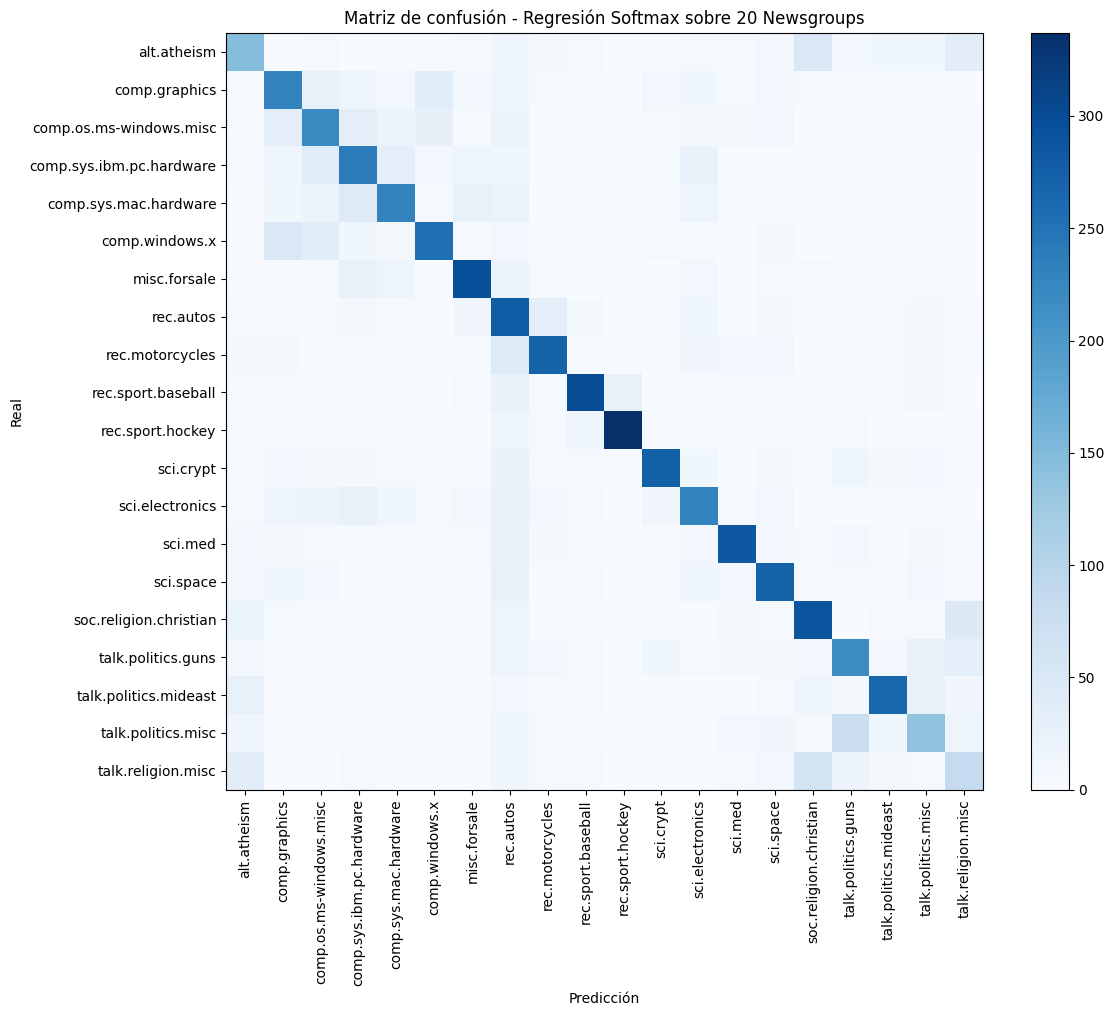

In [48]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

## 9. Preguntas de reflexión

### Sobre Regresión Softmax (teoría)

**1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?**

La regresión logística binaria permite clasificar entre dos clases, mientras que la regresión softmax extiende esta idea a múltiples clases. En lugar de calcular un score para una sola clase frente a otra, la regresión softmax calcula un logit para cada una de las clases y luego permite obtener la clase con mayor probabilidad.

Si `NUM_CLASSES = 2`, el modelo seguiría funcionando como una clasificación binaria, utilizando dos logits. Conceptualmente, sería equivalente a una regresión logística binaria.

---

**2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?**

`CrossEntropyLoss` recibe directamente los logits del modelo y realiza internamente una operación equivalente a `log_softmax` seguida de la función de pérdida correspondiente.

Por eso, en este TP el `forward` devuelve los logits directamente y no aplica `softmax`.

Si se aplicara `softmax` antes de `CrossEntropyLoss`, se estaría haciendo una transformación que no es necesaria y puede producir problemas numéricos y un entrenamiento menos estable.

---

**3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?**

La regresión softmax tiene una frontera de decisión lineal, ya que el modelo solamente utiliza una capa lineal y no posee capas ocultas ni funciones de activación no lineales.

Por lo tanto, puede separar las clases mediante fronteras lineales. Si el problema requiere una frontera no lineal para separar correctamente las clases, este modelo tiene una limitación y puede no lograr una buena clasificación.

---

**4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?**

El modelo utilizado en este TP tiene solamente una capa lineal, por lo que es un modelo simple y solamente puede aprender relaciones lineales entre las características de entrada y las clases.

Una red neuronal con capas ocultas puede aprender relaciones no lineales y representaciones más complejas.

La regresión softmax puede ser adecuada cuando se busca un modelo simple, rápido e interpretable. Una red con capas ocultas sería útil cuando las relaciones entre los datos y las clases son más complejas y una separación lineal no resulta suficiente.

---

### Sobre frameworks y herramientas

**5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?**

Una ventaja de PyTorch es que permite tener mayor control sobre la arquitectura del modelo, el entrenamiento, el optimizador, las métricas y el uso de hardware como GPU. Además, el mismo código puede extenderse fácilmente a modelos neuronales más complejos.

Como desventaja, requiere escribir más código y configurar manualmente partes que `scikit-learn` ya resuelve, como el entrenamiento del clasificador y algunos aspectos del manejo de los datos.

En este TP, PyTorch resulta útil porque permite observar de forma explícita el funcionamiento de una regresión softmax y del proceso de entrenamiento.

---

**6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?**

MLflow se utilizó para registrar los experimentos, incluyendo hiperparámetros, métricas y el modelo entrenado.

TensorBoard se utilizó principalmente para visualizar la evolución de métricas del entrenamiento, como `loss` y `accuracy`, a lo largo de las épocas.

Por lo tanto, TensorBoard resulta especialmente útil para observar visualmente cómo evoluciona el entrenamiento, mientras que MLflow permite organizar y registrar los distintos experimentos y sus resultados.

---

**7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?**

Optuna permitió explorar automáticamente distintas combinaciones de hiperparámetros de preprocesamiento y entrenamiento.

En este TP se probaron diferentes opciones de eliminación de stopwords, normalización, n-gramas, cantidad máxima de características, `min_df`, learning rate y batch size.

Esto permitió encontrar una combinación con una accuracy de validación de aproximadamente `0.7309`, evitando tener que probar manualmente todas las combinaciones posibles.

---

### Sobre el experimento

**8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?**

La mejor combinación encontrada por Optuna fue:

* `remove_stopwords = True`
* `normalization = lemmatize`
* `ngram_range = 1gram` (solamente unigramas)
* `max_features = 10000`
* `min_df = 2`
* `lr ≈ 0.00779`
* `batch_size = 32`

Esta configuración obtuvo una accuracy de validación de aproximadamente `0.7309`.

El resultado es razonable: lematizar con stopwords removidas es una normalización conservadora que no deforma las palabras como el stemming. Sin embargo, la ventaja sobre no normalizar es pequeña (0.7309 vs 0.7243), por lo que esta búsqueda no permite afirmar que la lematización sea la causa de la mejora.

---

**9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?**

La matriz de confusión muestra especialmente confusiones entre categorías con contenido temático similar.

Por ejemplo, se observa una confusión importante entre `talk.politics.misc` y `talk.politics.guns`, y también entre `talk.religion.misc` y `soc.religion.christian`.

En las categorías de computación también aparecen confusiones entre algunos grupos relacionados con hardware y sistemas operativos, como `comp.os.ms-windows.misc`, `comp.sys.ibm.pc.hardware` y `comp.sys.mac.hardware`.

Esto puede ocurrir porque categorías relacionadas utilizan vocabulario similar. Como el modelo utiliza TF-IDF y una única capa lineal, la decisión se basa principalmente en la presencia y peso de determinadas palabras, sin poder representar relaciones semánticas más complejas.

---

**10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?**

Sí, podría cambiar. Una red neuronal con capas ocultas puede aprender relaciones no lineales y combinaciones más complejas entre las características de entrada.

Por este motivo, podría distinguir mejor algunas categorías que tienen vocabulario similar y que actualmente se confunden.

Sin embargo, utilizar una red con capas ocultas no garantiza que todas las confusiones desaparezcan, ya que el resultado también depende de la arquitectura, el entrenamiento y los datos utilizados.